# Démo · Répartir les tickets entre les conseillers

**Question :** quel taux de délais tenus obtenons-nous avec notre répartition, et avec la répartition naïve ?

| | Gloutonne | Naïve (référence) |
|---|---|---|
| Ordre des tickets | du plus urgent au moins urgent (notre file de priorité) | du plus ancien au plus récent |
| Choix du conseiller | le compétent le **moins occupé** (charge / capacité) | le **premier** compétent de la liste qui a encore de la place |

**Modèle du délai tenu :** chaque conseiller traite sa liste dans l'ordre, un ticket toutes les 20 minutes à partir du début ;
le k-ième ticket finit à `début + k × 20 min`. Il est tenu s'il finit **au plus tard** à son échéance. Un ticket non affecté est raté.

> **Confidentialité :** ce notebook n'affiche que des comptes, des taux et des identifiants de conseillers. Aucun ticket, aucun message.

Exécuter les cellules dans l'ordre.

In [1]:
import os
import sys
from collections import Counter
from datetime import datetime, timedelta
from pathlib import Path

# Se placer à la racine du dépôt (le dossier qui contient moteur_sav/).
racine = Path.cwd()
while not (racine / "moteur_sav").exists() and racine != racine.parent:
    racine = racine.parent
os.chdir(racine)
sys.path.insert(0, str(racine))
sys.path.insert(0, str(racine / "tests"))  # pour la fabrique de tickets inventés

import matplotlib.pyplot as plt

from fabrique import fabriquer_ticket
from moteur_sav.affectation import NON_AFFECTES, affecter, affecter_naif, taux_sla
from moteur_sav.file_priorite import FilePriorite
from moteur_sav.ingestion import charger_agents, charger_tickets
from moteur_sav.modeles import Agent

%matplotlib inline

# Couleurs fixes par répartition (lisibles par les daltoniens), gris pour les références.
COULEURS = {"gloutonne": "#2a78d6", "naïve": "#eb6834", "variante": "#1baf7a"}
GRIS = "#8a8a8a"

In [2]:
def tableau(entetes, lignes):
    """Tableau texte aligné, sans bibliothèque."""
    lignes = [[str(c) for c in ligne] for ligne in lignes]
    largeurs = [max(len(str(e)), *(len(l[i]) for l in lignes)) if lignes else len(str(e))
                for i, e in enumerate(entetes)]
    fmt = lambda l: " | ".join(c.ljust(largeurs[i]) for i, c in enumerate(l)).rstrip()
    return "\n".join([fmt([str(e) for e in entetes]), "-+-".join("-" * w for w in largeurs), *map(fmt, lignes)])


def detail(affectations, tickets, debut, duree_minutes=20):
    """Pour chaque ticket affecté : conseiller, position, heure de fin, échéance, tenu ou non."""
    par_id = {t.id: t for t in tickets}
    pas = timedelta(minutes=duree_minutes)
    lignes = []
    for agent_id, ids in affectations.items():
        if agent_id == NON_AFFECTES:
            continue
        for k, ticket_id in enumerate(ids, start=1):
            fin = debut + k * pas
            lignes.append((agent_id, k, ticket_id, fin, par_id[ticket_id].echeance,
                           fin <= par_id[ticket_id].echeance))
    return lignes

## 1. Un petit exemple calculé à la main
Deux conseillers compétents pour les livraisons, capacité 2 chacun. Début le 14/03/2026 à 8 h. Tickets **inventés** :
- **A** : créé le 13/03 à 9 h, priorité 3, échéance le 16/03 à 9 h ;
- **U** : créé le 14/03 à 4 h 30, priorité 1, échéance le 14/03 à **8 h 30**.

La naïve sert A d'abord (plus ancien) et met U en 2e position chez AG-01 : fin à 8 h 40, trop tard.
La gloutonne sert U d'abord (plus urgent), puis donne A à AG-02, moins occupé : les deux finissent à 8 h 20.

In [3]:
debut_ex = datetime(2026, 3, 14, 8, 0)
ancien = fabriquer_ticket(id="A", cree_le="2026-03-13T09:00:00", priorite=3)
urgent = fabriquer_ticket(id="U", cree_le="2026-03-14T04:30:00", priorite=1)
lot_ex = [ancien, urgent]
agents_ex = [Agent("AG-01", "Exemple", frozenset({"livraison"}), 2),
             Agent("AG-02", "Exemple", frozenset({"livraison"}), 2)]

for nom, repartir in [("gloutonne", affecter), ("naïve", affecter_naif)]:
    aff = repartir(lot_ex, agents_ex)
    print(f"=== {nom} : {aff}")
    lignes = [(a, k, i, f"{fin:%H:%M}", f"{ech:%d/%m %H:%M}", "oui" if ok else "NON")
              for a, k, i, fin, ech, ok in detail(aff, lot_ex, debut_ex)]
    print(tableau(("conseiller", "position", "ticket", "fin", "échéance", "tenu"), lignes))
    print(f"taux de délais tenus : {taux_sla(aff, lot_ex, debut_ex):.0%}\n")

=== gloutonne : {'AG-01': ['U'], 'AG-02': ['A'], 'non_affectes': []}
conseiller | position | ticket | fin   | échéance    | tenu
-----------+----------+--------+-------+-------------+-----
AG-01      | 1        | U      | 08:20 | 14/03 08:30 | oui
AG-02      | 1        | A      | 08:20 | 16/03 09:00 | oui
taux de délais tenus : 100%

=== naïve : {'AG-01': ['A', 'U'], 'AG-02': [], 'non_affectes': []}
conseiller | position | ticket | fin   | échéance    | tenu
-----------+----------+--------+-------+-------------+-----
AG-01      | 1        | A      | 08:20 | 16/03 09:00 | oui
AG-01      | 2        | U      | 08:40 | 14/03 08:30 | NON
taux de délais tenus : 50%



## 2. Le lot type
Tickets **non résolus** créés depuis le **28/09/2026**, traités à partir du **01/10/2026 à 8 h**, un ticket toutes les 20 minutes par conseiller.

In [4]:
# Jeu complet s'il a été généré (scripts/generer_donnees.py --n 25000), sinon l'échantillon versionné.
complet = Path("donnees/tickets.jsonl").exists()
tickets, rejets = charger_tickets("donnees/tickets.jsonl" if complet else "donnees/echantillon_tickets.jsonl")
agents = charger_agents("donnees/agents.csv" if complet else "donnees/echantillon_conseillers.csv")

DEBUT = datetime(2026, 10, 1, 8, 0)
PAS = timedelta(minutes=20)
lot = [t for t in tickets if t.statut != "resolu" and t.cree_le >= datetime(2026, 9, 28)]

print(f"{len(tickets)} tickets exploitables, dont {len(lot)} dans le lot.\n")
print(tableau(("priorité", "tickets"), sorted(Counter(f"P{t.priorite}" for t in lot).items())))
print()
print(tableau(("catégorie", "tickets"), Counter(t.categorie for t in lot).most_common()))

2439 tickets exploitables, dont 163 dans le lot.

priorité | tickets
---------+--------
P1       | 7
P2       | 33
P3       | 89
P4       | 34

catégorie      | tickets
---------------+--------
livraison      | 52
conseil_plante | 32
produit_abime  | 26
facturation    | 23
retour         | 19
autre          | 11


In [5]:
# Les conseillers : identifiant, compétences, capacité (pas de nom affiché).
print(tableau(("conseiller", "capacité", "compétences"),
              [(a.agent_id, a.capacite_jour, ", ".join(sorted(a.competences))) for a in agents]))
print(f"\nCapacité totale : {sum(a.capacite_jour for a in agents)} tickets pour un lot de {len(lot)}.")

conseiller | capacité | compétences
-----------+----------+---------------------------------
AG-01      | 40       | livraison, retour
AG-02      | 35       | autre, livraison
AG-03      | 30       | conseil_plante, produit_abime
AG-04      | 25       | conseil_plante
AG-05      | 40       | autre, facturation, retour
AG-06      | 30       | facturation
AG-07      | 30       | produit_abime, retour
AG-08      | 35       | facturation, livraison
AG-09      | 25       | autre, conseil_plante
AG-10      | 45       | livraison, produit_abime, retour
AG-11      | 30       | autre, facturation
AG-12      | 25       | conseil_plante, livraison

Capacité totale : 390 tickets pour un lot de 163.


In [6]:
# Un ticket dont l'échéance tombe avant la fin du tout premier traitement (8 h 20) est perdu d'avance.
perdus = {t.id for t in lot if t.echeance < DEBUT + PAS}
sauvables = len(lot) - len(perdus)
MAXIMUM = sauvables / len(lot)
print(f"Déjà impossibles à tenir : {len(perdus)} tickets sur {len(lot)}")
print(f"Taux maximal atteignable, quelle que soit la répartition : {MAXIMUM:.1%}")
print(tableau(("priorité", "perdus d'avance", "dans le lot"),
              [(f"P{p}", sum(t.id in perdus for t in lot if t.priorite == p),
                sum(t.priorite == p for t in lot)) for p in (1, 2, 3, 4)]))

Déjà impossibles à tenir : 30 tickets sur 163
Taux maximal atteignable, quelle que soit la répartition : 81.6%
priorité | perdus d'avance | dans le lot
---------+-----------------+------------
P1       | 7               | 7
P2       | 23              | 33
P3       | 0               | 89
P4       | 0               | 34


## 3. Comparaison des deux répartitions

In [7]:
resultats = {"gloutonne": affecter(lot, agents), "naïve": affecter_naif(lot, agents)}

def bilan(aff):
    charges = [len(ids) for a, ids in aff.items() if a != NON_AFFECTES]
    tenus = sum(ok for *_, ok in detail(aff, lot, DEBUT))
    fin_max = DEBUT + max(charges) * PAS
    return (f"{taux_sla(aff, lot, DEBUT):.1%}", tenus, f"{tenus / sauvables:.0%}",
            len(aff[NON_AFFECTES]), f"{min(charges)} à {max(charges)}", f"{fin_max:%d/%m %H:%M}")

print(tableau(("répartition", "délais tenus", "tickets tenus", "des sauvables", "non affectés",
               "charge par conseiller", "fin du dernier ticket"),
              [(nom, *bilan(aff)) for nom, aff in resultats.items()]))
print(f"\nMaximum atteignable : {MAXIMUM:.1%} ({sauvables} tickets sauvables)")

répartition | délais tenus | tickets tenus | des sauvables | non affectés | charge par conseiller | fin du dernier ticket
------------+--------------+---------------+---------------+--------------+-----------------------+----------------------
gloutonne   | 81.6%        | 133           | 100%          | 0            | 10 à 19               | 01/10 14:20
naïve       | 79.1%        | 129           | 97%           | 0            | 0 à 40                | 01/10 21:20

Maximum atteignable : 81.6% (133 tickets sauvables)


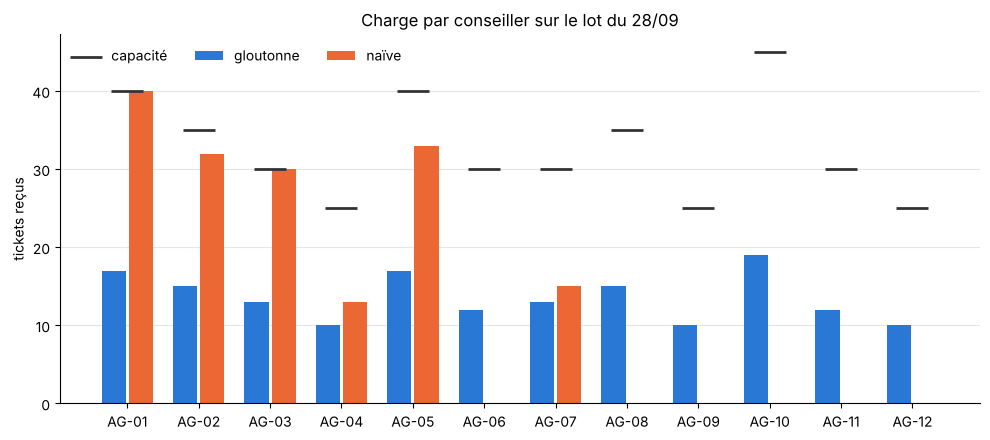

In [8]:
# Charge de chaque conseiller : la naïve remplit les premiers de la liste, la gloutonne équilibre.
ids_agents = [a.agent_id for a in agents]
x = range(len(ids_agents))
largeur = 0.38

fig, ax = plt.subplots(figsize=(10, 4.5))
for decalage, (nom, aff) in zip((-largeur / 2, largeur / 2), resultats.items()):
    ax.bar([i + decalage for i in x], [len(aff[a]) for a in ids_agents], width=largeur - 0.04,
           color=COULEURS[nom], label=nom)
ax.scatter(list(x), [a.capacite_jour for a in agents], marker="_", s=500, color="#333333",
           linewidths=2, label="capacité", zorder=3)
ax.set_xticks(list(x), ids_agents)
ax.set_ylabel("tickets reçus")
ax.set_title("Charge par conseiller sur le lot du 28/09")
ax.grid(axis="y", color="#e5e5e5")
ax.set_axisbelow(True)
for cote in ("top", "right"):
    ax.spines[cote].set_visible(False)
ax.legend(frameon=False, ncol=3)
plt.tight_layout()
plt.show()

priorité | gloutonne | naïve | maximum
---------+-----------+-------+--------
P1       | 0%        | 0%    | 0%
P2       | 30%       | 18%   | 30%
P3       | 100%      | 100%  | 100%
P4       | 100%      | 100%  | 100%


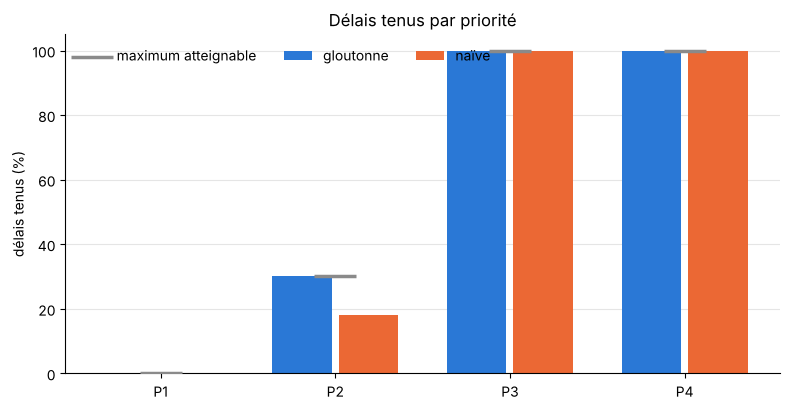

In [9]:
# Taux de délais tenus par priorité, comparé au maximum atteignable de chaque priorité.
def taux_par_priorite(aff):
    # Identifiants des tickets tenus (3e et 6e valeurs de chaque ligne du détail).
    tenus = {ticket_id for _, _, ticket_id, _, _, ok in detail(aff, lot, DEBUT) if ok}
    return {p: sum(t.id in tenus for t in lot if t.priorite == p) / max(1, sum(t.priorite == p for t in lot))
            for p in (1, 2, 3, 4)}

taux_prio = {nom: taux_par_priorite(aff) for nom, aff in resultats.items()}
max_prio = {p: sum(t.id not in perdus for t in lot if t.priorite == p) / max(1, sum(t.priorite == p for t in lot))
            for p in (1, 2, 3, 4)}

print(tableau(("priorité", "gloutonne", "naïve", "maximum"),
              [(f"P{p}", f"{taux_prio['gloutonne'][p]:.0%}", f"{taux_prio['naïve'][p]:.0%}", f"{max_prio[p]:.0%}")
               for p in (1, 2, 3, 4)]))

fig, ax = plt.subplots(figsize=(8, 4.2))
for decalage, nom in zip((-largeur / 2, largeur / 2), ("gloutonne", "naïve")):
    ax.bar([p + decalage for p in (1, 2, 3, 4)], [100 * taux_prio[nom][p] for p in (1, 2, 3, 4)],
           width=largeur - 0.04, color=COULEURS[nom], label=nom)
ax.scatter([1, 2, 3, 4], [100 * max_prio[p] for p in (1, 2, 3, 4)], marker="_", s=900, color=GRIS,
           linewidths=2.5, label="maximum atteignable", zorder=3)
ax.set_xticks([1, 2, 3, 4], ["P1", "P2", "P3", "P4"])
ax.set_ylim(0, 105)
ax.set_ylabel("délais tenus (%)")
ax.set_title("Délais tenus par priorité")
ax.grid(axis="y", color="#e5e5e5")
ax.set_axisbelow(True)
for cote in ("top", "right"):
    ax.spines[cote].set_visible(False)
ax.legend(frameon=False, ncol=3, loc="upper left")
plt.tight_layout()
plt.show()

## 4. Une limite : les tickets déjà perdus passent en premier
La gloutonne sert d'abord les échéances les plus proches, donc les tickets **déjà en retard**.
Ils prennent les premières places des conseillers alors qu'ils ne peuvent plus être tenus.

In [10]:
glouton = resultats["gloutonne"]
places = [(a, k) for a, ids in glouton.items() if a != NON_AFFECTES
          for k, i in enumerate(ids, start=1) if i in perdus]
print(f"Places occupées par des tickets perdus d'avance : {len(places)}")
print(f"Dont parmi les 5 premières places d'un conseiller : {sum(k <= 5 for _, k in places)}")

Places occupées par des tickets perdus d'avance : 30
Dont parmi les 5 premières places d'un conseiller : 30


### Exploration (défi bonus « tickets sauvables ») : servir d'abord ceux qu'on peut encore sauver
Même gloutonne, mais les tickets perdus d'avance sont **reportés après tous les autres** : la clé devient
`(perdu ?, clé d'urgence)`. Cette variante est codée ici pour la mesure ; elle n'est pas dans le module.

In [11]:
def affecter_sauvables(tickets, agents, debut, duree_minutes=20):
    perdu = lambda t: t.echeance < debut + timedelta(minutes=duree_minutes)
    aff = {a.agent_id: [] for a in agents}
    aff[NON_AFFECTES] = []
    file = FilePriorite()
    for t in tickets:
        file.ajouter(t, (perdu(t), t.cle_urgence()))   # False < True : les sauvables d'abord
    while not file.est_vide():
        t = file.extraire()
        candidats = [a for a in agents
                     if a.sait_traiter(t.categorie) and len(aff[a.agent_id]) < a.capacite_jour]
        if not candidats:
            aff[NON_AFFECTES].append(t.id)
            continue
        choisi = min(candidats, key=lambda a: (len(aff[a.agent_id]) / a.capacite_jour, a.agent_id))
        aff[choisi.agent_id].append(t.id)
    return aff

resultats["variante"] = affecter_sauvables(lot, agents, DEBUT)
print(tableau(("répartition", "délais tenus", "tickets tenus", "des sauvables", "non affectés",
               "charge par conseiller", "fin du dernier ticket"),
              [(nom, *bilan(aff)) for nom, aff in resultats.items()]))
print(f"\nMaximum atteignable : {MAXIMUM:.1%}")

répartition | délais tenus | tickets tenus | des sauvables | non affectés | charge par conseiller | fin du dernier ticket
------------+--------------+---------------+---------------+--------------+-----------------------+----------------------
gloutonne   | 81.6%        | 133           | 100%          | 0            | 10 à 19               | 01/10 14:20
naïve       | 79.1%        | 129           | 97%           | 0            | 0 à 40                | 01/10 21:20
variante    | 81.6%        | 133           | 100%          | 0            | 11 à 18               | 01/10 14:00

Maximum atteignable : 81.6%


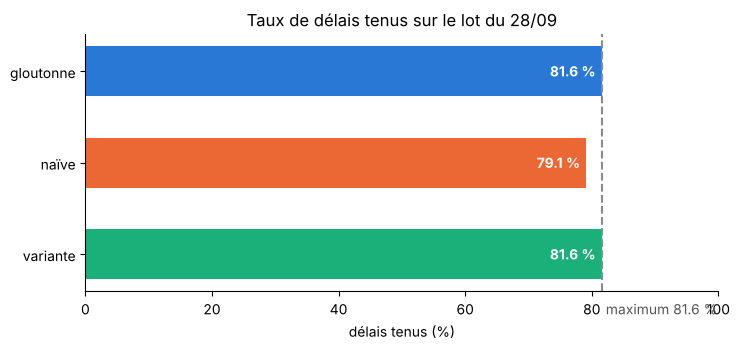

In [12]:
# Les trois répartitions face au maximum atteignable.
noms = list(resultats)
valeurs = [100 * taux_sla(resultats[n], lot, DEBUT) for n in noms]

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(noms, valeurs, color=[COULEURS[n] for n in noms], height=0.55)
ax.axvline(100 * MAXIMUM, color=GRIS, linestyle="--", linewidth=1.5)
ax.text(100 * MAXIMUM, len(noms) - 0.4, f" maximum {100 * MAXIMUM:.1f} %", color="#555555", va="center")
for i, v in enumerate(valeurs):
    ax.text(v - 1, i, f"{v:.1f} %", va="center", ha="right", color="white", fontweight="bold")
ax.set_xlim(0, 100)
ax.set_xlabel("délais tenus (%)")
ax.set_title("Taux de délais tenus sur le lot du 28/09")
ax.invert_yaxis()
for cote in ("top", "right"):
    ax.spines[cote].set_visible(False)
plt.tight_layout()
plt.show()

## 5. Conclusion chiffrée
Le texte ci-dessous est calculé à partir des résultats : il reste juste si les données ou le code changent.

In [13]:
t_g, t_n = (taux_sla(resultats[n], lot, DEBUT) for n in ("gloutonne", "naïve"))
n_g, n_n = (sum(ok for *_, ok in detail(resultats[n], lot, DEBUT)) for n in ("gloutonne", "naïve"))
c_g, c_n = ([len(ids) for a, ids in resultats[n].items() if a != NON_AFFECTES] for n in ("gloutonne", "naïve"))
t_v = taux_sla(resultats["variante"], lot, DEBUT)

print(f"Sur les {len(lot)} tickets non résolus créés depuis le 28/09, la répartition gloutonne tient "
      f"{t_g:.1%} des délais, contre {t_n:.1%} pour la naïve : {n_g - n_n:+d} délais avec les mêmes conseillers.")
print(f"{len(perdus)} tickets étaient déjà perdus au départ : le maximum possible est {MAXIMUM:.1%}. "
      f"La gloutonne tient {n_g / sauvables:.0%} des tickets sauvables, la naïve {n_n / sauvables:.0%}.")
print(f"Charge par conseiller : de {min(c_g)} à {max(c_g)} pour la gloutonne, "
      f"de {min(c_n)} à {max(c_n)} pour la naïve.")
print(f"Limite et suite : reporter les tickets perdus d'avance donne {t_v:.1%} ({100 * (t_v - t_g):+.1f} points).")

Sur les 163 tickets non résolus créés depuis le 28/09, la répartition gloutonne tient 81.6% des délais, contre 79.1% pour la naïve : +4 délais avec les mêmes conseillers.
30 tickets étaient déjà perdus au départ : le maximum possible est 81.6%. La gloutonne tient 100% des tickets sauvables, la naïve 97%.
Charge par conseiller : de 10 à 19 pour la gloutonne, de 0 à 40 pour la naïve.
Limite et suite : reporter les tickets perdus d'avance donne 81.6% (+0.0 points).
